In [2]:
#31.Create an imbalanced problem, either by taking a real imbalanced dataset or by
#keeping only a small random sample of the positive rows in a balanced one.
import seaborn as sns
import pandas as pd
df = sns.load_dataset("titanic")
majority = df[df["survived"] == 0]
minority = df[df["survived"] == 1]
minority_small = minority.sample(n=50, random_state=42)
df_imbalanced = pd.concat([majority, minority_small])


In [4]:
#32.Train a baseline model and record its accuracy right next to its recall on the rare class,
#so you can see the gap for yourself.
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
X = df_imbalanced[["pclass", "sex", "age", "sibsp", "parch"]]
y = df_imbalanced["survived"]
X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.2,random_state=42,stratify=y)
numeric_features = ["pclass", "age", "sibsp", "parch"]
categorical_features = ["sex"]
preprocessor = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)])
model = Pipeline([("preprocessor", preprocessor),("classifier", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
from sklearn.metrics import accuracy_score, recall_score
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, pos_label=1)
print("Accuracy:", accuracy)
print("Recall:", recall)

Accuracy: 0.9333333333333333
Recall: 0.4


In [5]:
balanced_model = Pipeline([("preprocessor", preprocessor),("classifier", LogisticRegression(
        max_iter=1000,class_weight="balanced"))])
balanced_model.fit(X_train, y_train)
y_pred_balanced = balanced_model.predict(X_test)
from sklearn.metrics import precision_score, recall_score, f1_score
precision_balanced = preci   sion_score(y_test, y_pred_balanced, pos_label=1)
recall_balanced = recall_score(y_test, y_pred_balanced, pos_label=1)
f1_balanced = f1_score(y_test, y_pred_balanced, pos_label=1)
print("Balanced Precision:", precision_balanced)
print("Balanced Recall:", recall_balanced)
print("Balanced F1 Score:", f1_balanced)

Balanced Precision: 0.34782608695652173
Balanced Recall: 0.8
Balanced F1 Score: 0.48484848484848486


Threshold: 0.1 | Precision: 0.095 | Recall: 1.000
Threshold: 0.2 | Precision: 0.175 | Recall: 1.000
Threshold: 0.3 | Precision: 0.222 | Recall: 1.000
Threshold: 0.4 | Precision: 0.250 | Recall: 0.900
Threshold: 0.5 | Precision: 0.348 | Recall: 0.800
Threshold: 0.6 | Precision: 0.412 | Recall: 0.700
Threshold: 0.7 | Precision: 0.500 | Recall: 0.600
Threshold: 0.8 | Precision: 0.714 | Recall: 0.500
Threshold: 0.9 | Precision: 0.750 | Recall: 0.300


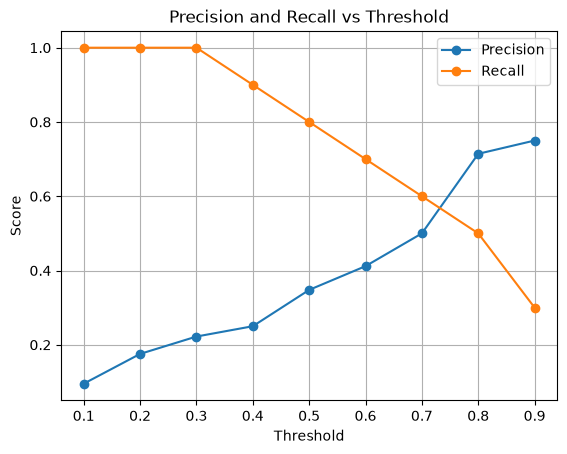

In [7]:
y_prob = balanced_model.predict_proba(X_test)[:, 1]
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
from sklearn.metrics import precision_score, recall_score
precisions = []
recalls = []
for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)
    precisions.append(
        precision_score(y_test, y_pred_threshold, pos_label=1))
    recalls.append(
        recall_score(y_test, y_pred_threshold, pos_label=1))
for threshold, precision, recall in zip(thresholds, precisions, recalls):
    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f}" )
import matplotlib.pyplot as plt

plt.plot(thresholds, precisions, marker="o", label="Precision")
plt.plot(thresholds, recalls, marker="o", label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid()
plt.show()

Average Precision: 0.5524728525577421
ROC AUC: 0.9254545454545454


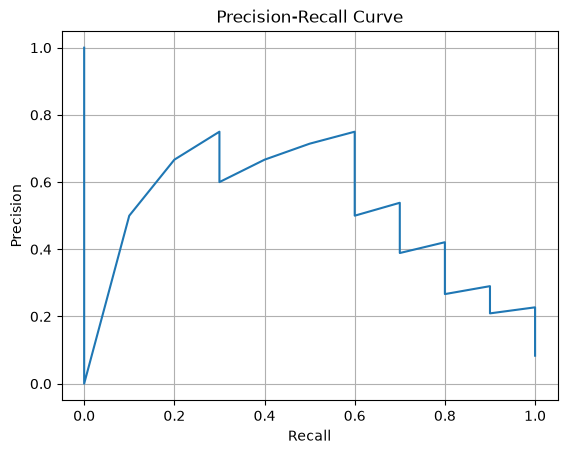

In [8]:
#36.	Plot the precision recall curve, report average precision beside the ROC AUC,
#and note which of the two told you more about this problem.
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
# Probability of positive class (class 1)
y_prob = balanced_model.predict_proba(X_test)[:, 1]
# Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
# Average Precision
average_precision = average_precision_score(y_test, y_prob)
# ROC AUC
roc_auc = roc_auc_score(y_test, y_prob)
print("Average Precision:", average_precision)
print("ROC AUC:", roc_auc)
# Plot Precision-Recall Curve
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()
plt.show()